# Reprodução do Wi-Chat — Notebook 01: dados reais (Alsaify et al., 2020)

**Por que trocamos de dataset:** o link do UT-HAR (Yousefi et al.) foi removido do Google Drive, e o dataset passou para o IEEE DataPort, onde o acesso exige assinatura. Usamos então o dataset de **Alsaify et al. (2020)**, publicado no *Mendeley Data* com licença **CC BY 4.0** (aberto, sem login).

**Por que ele serve bem:**
- mesma placa (Intel 5300) e mesma ferramenta (Linux 802.11n CSI Tool) do artigo;
- **3 ambientes** (duas salas com linha de visada e uma sem), como o Wi-Chat, que usou quarto, cozinha e sala;
- 30 pessoas, 20 repetições de cada experimento;
- as atividades já vêm **separadas em arquivos** (sentado parado, queda, deitado, caminhada, giro etc.), o que facilita o recorte.

**Diferenças em relação ao artigo (documentar no relatório):**

| | Wi-Chat | Este dataset |
|---|---|---|
| Frequência | 5,32 GHz, 40 MHz | 2,4 GHz, 20 MHz |
| Taxa | 1000 pacotes/s | 320 pacotes/s |
| Antenas | 3 × 3 | 1 × 3 (90 séries) |
| "No event" | ambiente vazio | pessoa parada |

Um efeito físico da diferença de frequência: em 2,4 GHz o comprimento de onda é ~12,5 cm, contra ~5,6 cm em 5,3 GHz. O mesmo movimento produz **menos picos e vales** na amplitude, o que pode afetar as regras do prompt baseadas em contar picos.

**Classes que vamos montar (janelas de 5 s):**

| Classe | Como montamos |
|---|---|
| `walk` | experimento C3 (ir até o receptor, girar, voltar, girar), janela no meio da gravação |
| `fall` | experimentos C1 e C2: 1 s parado → queda → deitado, até completar 5 s |
| `no event` | trechos parados do experimento C4 (sentado parado ou em pé parado) |

**Saída:** `alsaify_segmentos.npz` + `alsaify_meta.csv` no seu Google Drive.

**Ambiente:** CPU basta. Download de ~2 GB, total de uns 10–20 minutos.

## 1. Configuração e Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
MATERIA  = '/content/drive/MyDrive/Semestres/10 Semestre/Tópicos em Computação'
if not os.path.isdir(MATERIA):
    raise FileNotFoundError(f'Pasta da matéria não encontrada: {MATERIA}\n'
                            'Confira o nome exato com: !ls "/content/drive/MyDrive/Semestres"')
PROJ     = f'{MATERIA}/wichat_repro'
DATA_OUT = f'{PROJ}/data'
RAW      = '/content/alsaify_raw'

SEED = 42
FS   = 320          # pacotes por segundo neste dataset
WIN  = 5 * FS       # janela de 5 s = 1600 pacotes
ENVS = [1, 2, 3]    # ambientes a usar (3 = sem linha de visada)

os.makedirs(DATA_OUT, exist_ok=True)
os.makedirs(RAW, exist_ok=True)
print('Saídas vão para:', DATA_OUT)

Mounted at /content/drive
Saídas vão para: /content/drive/MyDrive/Semestres/10 Semestre/Tópicos em Computação/wichat_repro/data


## 2. Download pelo Mendeley Data (~2 GB)

Usamos a API pública do Mendeley. Os arquivos vêm como um zip por pessoa, separados por ambiente, e cada um é conferido pelo hash SHA-256 publicado. Se você rodar de novo, o que já foi baixado é pulado.

**Se a API falhar:** baixe os arquivos pelo navegador em https://data.mendeley.com/datasets/v38wjmz6f6/1, **sem descompactar**, e suba-os para a pasta `wichat_repro/dados_brutos` dentro da pasta da matéria no Drive. Depois pule a célula de download e rode a seguinte, que encontra os arquivos lá sozinha.

In [3]:
import requests, hashlib
from tqdm.auto import tqdm

API = 'https://data.mendeley.com/public-api/datasets/v38wjmz6f6'
VERSION = 1

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for bloco in iter(lambda: f.read(1 << 20), b''):
            h.update(bloco)
    return h.hexdigest()

pastas = requests.get(f'{API}/folders/{VERSION}', timeout=60).json()
arquivos = []
for p in pastas:
    lst = requests.get(f'{API}/files', params={'folder_id': p['id'], 'version': VERSION}, timeout=60).json()
    for it in lst:
        d = it['content_details']
        arquivos.append(dict(pasta=p['name'], nome=it['filename'], size=d['size'],
                             sha=d['sha256_hash'], url=d['download_url']))
print(f'{len(arquivos)} arquivos listados, {sum(a["size"] for a in arquivos)/1e9:.2f} GB no total')

for a in tqdm(arquivos, desc='download'):
    env = int(a['pasta'].split()[-1])
    if env not in ENVS:
        continue
    destino = os.path.join(RAW, a['pasta'], a['nome'])
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    if os.path.exists(destino) and os.path.getsize(destino) == a['size'] and sha256(destino) == a['sha']:
        continue
    with requests.get(a['url'], stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(destino + '.part', 'wb') as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    if sha256(destino + '.part') != a['sha']:
        raise RuntimeError(f'Hash não confere: {a["nome"]} (rode a célula de novo)')
    os.replace(destino + '.part', destino)
print('Download concluído.')

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [4]:
# Usa os arquivos baixados manualmente que estiverem em dados_brutos (procura em subpastas também).
import zipfile, glob, shutil
from tqdm.auto import tqdm

PASTA_MANUAL = f'{PROJ}/dados_brutos'
os.makedirs(PASTA_MANUAL, exist_ok=True)

manuais = sorted(glob.glob(f'{PASTA_MANUAL}/**/*.zip', recursive=True))
print(f'{len(manuais)} zips encontrados em dados_brutos, '
      f'{sum(os.path.getsize(f) for f in manuais)/1e9:.2f} GB no total')

for f in tqdm(manuais, desc='copiando para o Colab'):
    rel = os.path.relpath(f, PASTA_MANUAL)          # ex.: Environment 1/Subject 1.zip
    if not zipfile.is_zipfile(f):
        print('  ⚠ arquivo corrompido ou incompleto:', rel); continue
    with zipfile.ZipFile(f) as zf:
        nomes = zf.namelist()
    if any(n.lower().endswith('.zip') for n in nomes):
        zipfile.ZipFile(f).extractall(os.path.join(RAW, os.path.dirname(rel)))   # zip com zips dentro
    elif any(n.lower().endswith('.csv') for n in nomes):
        destino = os.path.join(RAW, rel)                                          # zip com os CSVs
        os.makedirs(os.path.dirname(destino), exist_ok=True)
        if not os.path.exists(destino) or os.path.getsize(destino) != os.path.getsize(f):
            shutil.copy(f, destino)
    else:
        print('  ⚠ zip sem CSVs dentro:', rel)

ZIPS = sorted(glob.glob(f'{RAW}/**/*.zip', recursive=True))
print(len(ZIPS), 'zips com dados prontos para leitura (o esperado são 30, um por pessoa).')

30 zips encontrados em dados_brutos, 2.21 GB no total


copiando para o Colab:   0%|          | 0/30 [00:00<?, ?it/s]

30 zips com dados prontos para leitura (o esperado são 30, um por pessoa).


## 3. Inventário

Cada arquivo se chama `E<ambiente>_S<pessoa>_C<experimento>_A<atividade>_T<tentativa>.csv`. Uma **gravação** é a combinação (ambiente, pessoa, experimento, tentativa), e cada atividade dentro dela é um arquivo separado. A ordem das atividades em cada experimento segue a Tabela 1 do artigo do dataset:

In [5]:
import re, numpy as np, pandas as pd

ATIV = {1: 'sentado parado', 2: 'queda (de sentado)', 3: 'deitado', 4: 'em pé parado',
        5: 'queda (de pé)', 6: 'andar Tx→Rx', 7: 'girar', 8: 'andar Rx→Tx', 9: 'girar',
        10: 'levantar', 11: 'sentar', 12: 'pegar caneta'}
ORDEM = {1: [1, 2, 3], 2: [4, 5, 3], 3: [6, 7, 8, 9], 4: [1, 10, 4, 11], 5: [12]}

RE_NOME = re.compile(r'E(\d+)_S(\d+)_C(\d+)_A(\d+)_T(\d+)\.csv$', re.I)
linhas = []
for z in tqdm(ZIPS, desc='listando'):
    with zipfile.ZipFile(z) as zf:
        for entry in zf.namelist():
            m = RE_NOME.search(os.path.basename(entry))
            if m:
                E, S, Cx, A, T = map(int, m.groups())
                linhas.append(dict(zip=z, entry=entry, E=E, S=S, C=Cx, A=A, Tr=T))
inv = pd.DataFrame(linhas)
inv = inv[inv.E.isin(ENVS)].reset_index(drop=True)
print(len(inv), 'arquivos de atividade')
pd.crosstab(inv.A.map(lambda a: f'A{a} {ATIV[a]}'), inv.E, margins=True)

listando:   0%|          | 0/30 [00:00<?, ?it/s]

9000 arquivos de atividade


E,1,2,3,All
A,,,,
A1 sentado parado,400,400,400,1200
A10 levantar,200,200,200,600
A11 sentar,200,200,200,600
A12 pegar caneta,200,200,200,600
A2 queda (de sentado),200,200,200,600
A3 deitado,400,400,400,1200
A4 em pé parado,400,400,400,1200
A5 queda (de pé),200,200,200,600
A6 andar Tx→Rx,200,200,200,600


## 4. Leitor dos arquivos

Cada linha é um pacote: 13 colunas de metadados (a primeira é o timestamp, em microssegundos do relógio da placa) seguidas de 90 valores complexos escritos como texto `a+bi`. Ficamos com a **amplitude** |CSI|, como no artigo.

O leitor vetorizado é adaptado do repositório `baalsaify/wifi-csi-har` (licença MIT), do próprio autor do dataset.

In [6]:
N_META, N_CH = 13, 90
_zips_abertos = {}

def _zf(path):
    if path not in _zips_abertos:
        _zips_abertos[path] = zipfile.ZipFile(path)
    return _zips_abertos[path]

def le_arquivo(zip_path, entry):
    """Retorna (timestamps em µs, amplitude float32 [pacotes, 90])."""
    texto = _zf(zip_path).read(entry).decode('utf-8')
    header, _, corpo = texto.strip().partition('\n')
    if len(header.split(',')) != N_META + N_CH:
        raise ValueError(f'cabeçalho inesperado em {entry}')
    plano = corpo.replace('e+', 'e').replace('E+', 'E')
    plano = plano.replace('i', '').replace('+', ' ').replace(',', ' ')
    v = np.array(plano.split(), dtype=np.float64)
    linhas = v.reshape(-1, N_META + 2 * N_CH)
    csi = linhas[:, N_META::2] + 1j * linhas[:, N_META + 1::2]
    return linhas[:, 0], np.abs(csi).astype(np.float32)

r = inv.iloc[0]
ts, amp = le_arquivo(r.zip, r.entry)
print(os.path.basename(r.entry), '→', amp.shape, f'≈ {len(amp)/FS:.1f} s')
print('Intervalo mediano entre pacotes (ms):', np.median(np.diff(ts)) / 1000)

E1_S01_C05_A12_T14.csv → (1403, 90) ≈ 4.4 s
Intervalo mediano entre pacotes (ms): 3.125


## 5. Quanto dura cada atividade? As partes de uma gravação são contínuas?

O artigo do dataset define as durações por um diagrama de tempo que não está em texto, então medimos direto nos dados. Usamos uma amostra de pessoas e tentativas, só para não demorar.

Também checamos o **intervalo entre o último pacote de uma atividade e o primeiro da seguinte**. Se for de poucos milissegundos, as partes de uma gravação podem ser concatenadas, que é o que fazemos para montar a janela de queda.

In [7]:
amostra = inv[(inv.S.isin(inv.S.drop_duplicates().sample(6, random_state=SEED))) & (inv.Tr <= 4) & (inv.C <= 4)]
dur, gaps = [], []
for k, g in tqdm(amostra.groupby(['zip', 'E', 'S', 'C', 'Tr']), desc='medindo'):
    ant_fim = None
    for A in ORDEM[k[3]]:
        linha = g[g.A == A]
        if linha.empty:
            ant_fim = None; continue
        ts, amp = le_arquivo(k[0], linha.iloc[0].entry)
        dur.append(dict(C=k[3], A=A, atividade=ATIV[A], seg=len(amp) / FS))
        if ant_fim is not None:
            gaps.append(((ts[0] - ant_fim) % 2**32) / 1000)
        ant_fim = ts[-1]

dur = pd.DataFrame(dur)
print('Intervalo entre atividades consecutivas (ms): mediana', np.median(gaps), '| p90', np.percentile(gaps, 90))
dur.groupby(['C', 'A', 'atividade']).seg.describe()[['count', 'mean', 'min', '50%', 'max']].round(2)

medindo:   0%|          | 0/96 [00:00<?, ?it/s]

Intervalo entre atividades consecutivas (ms): mediana 3.124 | p90 3.174


count  mean   min   50%   max
C A  atividade                                        
1 1  sentado parado       24.0  2.93  2.77  2.93  3.00
  2  queda (de sentado)   24.0  3.90  3.71  3.91  3.99
  3  deitado              24.0  3.89  3.78  3.89  3.99
2 3  deitado              24.0  3.88  3.73  3.88  4.00
  4  em pé parado         24.0  2.92  2.81  2.93  3.00
  5  queda (de pé)        24.0  3.90  3.78  3.89  3.99
3 6  andar Tx→Rx          24.0  3.84  3.66  3.86  3.99
  7  girar                24.0  3.87  3.62  3.87  4.00
  8  andar Rx→Tx          24.0  3.88  3.67  3.89  4.00
  9  girar                24.0  3.87  3.70  3.86  3.98
4 1  sentado parado       24.0  4.85  4.64  4.87  4.99
  4  em pé parado         24.0  4.85  4.59  4.85  4.99
  10 levantar             24.0  3.10  2.94  3.10  3.20
  11 sentar               24.0  3.09  2.92  3.10  3.20

**O que conferir:** o intervalo mediano entre atividades deve ser de poucos ms (algo perto de 3 ms, que é 1/320 s). Se for de centenas de ms ou mais, me avise, porque aí a concatenação da queda precisa ser repensada.

Na tabela de durações, veja principalmente se os trechos parados do C4 (A1 e A4) passam de ~6 s. São eles que viram `no event`.

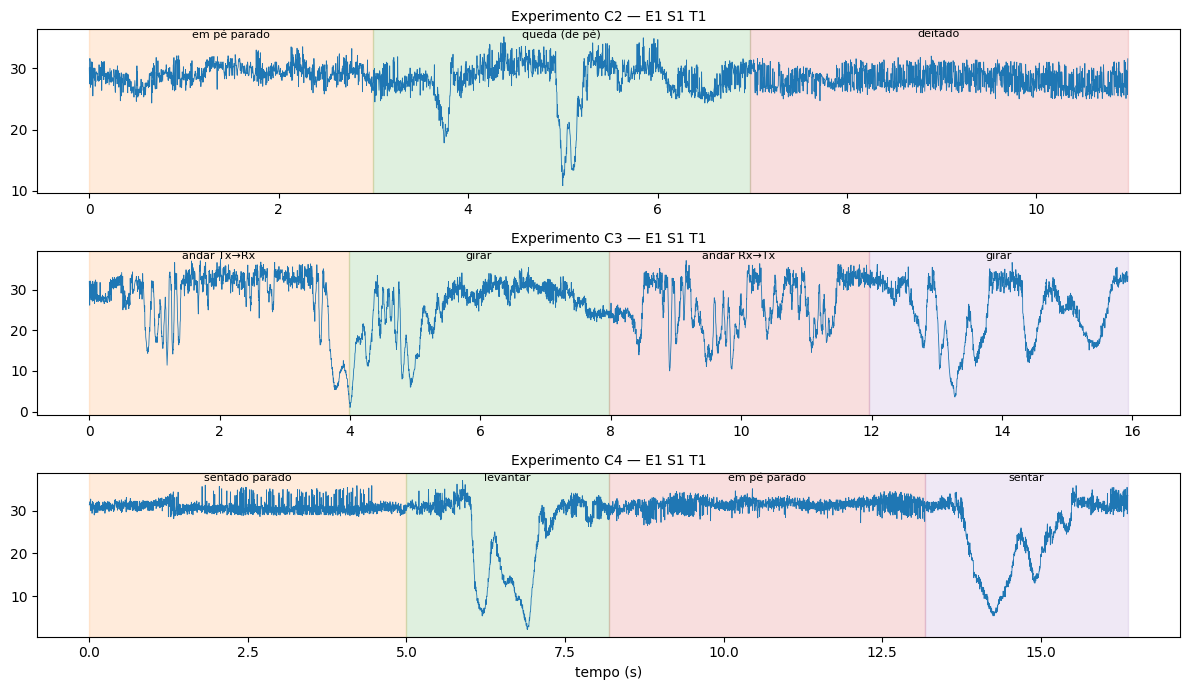

In [8]:
import matplotlib.pyplot as plt

def carrega_gravacao(zip_path, E, S, Cx, T):
    """Concatena as atividades de uma gravação na ordem do experimento."""
    g = inv[(inv.zip == zip_path) & (inv.E == E) & (inv.S == S) & (inv.C == Cx) & (inv.Tr == T)]
    partes, limites, pos = [], [], 0
    for A in ORDEM[Cx]:
        linha = g[g.A == A]
        if linha.empty:
            return None, None
        _, amp = le_arquivo(zip_path, linha.iloc[0].entry)
        partes.append(amp); limites.append((A, pos, pos + len(amp))); pos += len(amp)
    return np.concatenate(partes), limites

SUB = 14   # antena 1, subportadora 15 (só para visualizar)
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
for ax, Cx in zip(axes, [2, 3, 4]):
    r = inv[inv.C == Cx].iloc[0]
    amp, lim = carrega_gravacao(r.zip, r.E, r.S, r.C, r.Tr)
    ax.plot(np.arange(len(amp)) / FS, amp[:, SUB], lw=0.6)
    for i, (A, s, e) in enumerate(lim):
        ax.axvspan(s / FS, e / FS, color=f'C{i+1}', alpha=0.15)
        ax.text((s + e) / 2 / FS, ax.get_ylim()[1], ATIV[A], ha='center', va='top', fontsize=8)
    ax.set_title(f'Experimento C{Cx} — E{r.E} S{r.S} T{r.Tr}', fontsize=10)
axes[-1].set_xlabel('tempo (s)')
plt.tight_layout(); plt.show()

## 6. Regras de recorte (decisões metodológicas)

- **walk:** concatenamos a gravação C3 inteira (andar → girar → andar → girar) e pegamos 5 s **do meio**. A pessoa está se movendo o tempo todo, então a janela inteira é movimento.
- **fall:** concatenamos C1 (sentado → queda → deitado) ou C2 (em pé → queda → deitado). A janela começa `PRE_FALL` s antes da queda e precisa conter a queda inteira. O restante é a pessoa deitada, que é exatamente o padrão do artigo: um pico ou vale forte seguido de período estável. Metade das quedas vem de C1 e metade de C2.
- **no event:** trecho parado do C4 (A1 sentado ou A4 em pé, o mais longo), centrado, com `MARGEM` de folga em cada borda para não pegar o início ou o fim de um movimento.
- **Quantidade:** `N_POR_CLASSE` = 130 janelas por classe, ou seja, 390 no total, praticamente o mesmo tamanho do dataset do artigo (393). As janelas são sorteadas alternando entre pessoas, para todas as 30 aparecerem.

In [19]:
PRE_FALL     = 1.0       # segundos de "antes" na janela de queda
MARGEM       = 160       # 0,5 s de folga nos trechos parados
N_POR_CLASSE = 130

def janela_walk(rec):
    amp, lim = carrega_gravacao(*rec)
    if amp is None or len(amp) < WIN: return None
    st = (len(amp) - WIN) // 2
    return amp[st:st + WIN], st

def janela_fall(rec):
    amp, lim = carrega_gravacao(*rec)
    if amp is None: return None
    A_queda = 2 if rec[3] == 1 else 5
    _, s, e = next(l for l in lim if l[0] == A_queda)
    st = s - int(PRE_FALL * FS)
    if st < 0 or e > st + WIN or st + WIN > len(amp): return None
    return amp[st:st + WIN], st

MAX_EMPRESTIMO = int(0.4 * FS)   # até 0,4 s emprestados do início da atividade seguinte
RAZAO_MAX      = 1.5             # o trecho emprestado não pode variar mais que 1,5x o trecho parado
log_sem_evento = []              # segundos emprestados em cada janela aceita

def janela_sem_evento(rec):
    amp, lim = carrega_gravacao(*rec)            # C4: sentado parado → levantar → em pé parado → sentar
    if amp is None: return None
    for A_pref in (1, 4):                         # prefere sentado parado; em pé parado só se o A1 não servir
        for A, s, e in lim:
            if A != A_pref: continue
            n = e - s
            if n >= WIN:                          # trecho parado já tem 5 s ou mais: centraliza
                st, falta = s + (n - WIN) // 2, 0
            else:
                falta = WIN - n
                if falta > MAX_EMPRESTIMO or e + falta > len(amp): continue
                parado, emprest = amp[s:e], amp[e:e + falta]
                desvio_media = (np.abs(emprest.mean(0) - parado.mean(0)) / (parado.std(0) + 1e-6)).mean()
                razao_std = emprest.std(0).mean() / (parado.std(0).mean() + 1e-6)
                if desvio_media > 1.0 or razao_std > RAZAO_MAX:   # a pessoa já começou a se mexer
                    continue
                st = s
            log_sem_evento.append(falta / FS)
            return amp[st:st + WIN], st
    return None

## 7. Sorteio e recorte

In [20]:
rng = np.random.default_rng(SEED)
grav = inv.drop_duplicates(['zip', 'E', 'S', 'C', 'Tr'])[['zip', 'E', 'S', 'C', 'Tr']]

def rodizio(df, por):
    """Embaralha e intercala grupos (ex.: pessoas) para o sorteio ficar equilibrado."""
    grupos = [g.sample(frac=1, random_state=int(rng.integers(1e9))) for _, g in df.groupby(por)]
    rng.shuffle(grupos)
    saida = []
    for i in range(max(len(g) for g in grupos)):
        saida += [g.iloc[i] for g in grupos if i < len(g)]
    return pd.DataFrame(saida)

planos = {
    'walk':     (rodizio(grav[grav.C == 3], ['S']), janela_walk),
    'fall':     (rodizio(grav[grav.C.isin([1, 2])], ['S', 'C']), janela_fall),
    'no event': (rodizio(grav[grav.C == 4], ['S']), janela_sem_evento),
}

X_list, meta = [], []
for label, (cands, fn) in planos.items():
    ok = tentados = 0
    barra = tqdm(total=N_POR_CLASSE, desc=label)
    for _, r in cands.iterrows():
        if ok >= N_POR_CLASSE: break
        rec = (r.zip, r.E, r.S, r.C, r.Tr)
        tentados += 1
        try:
            res = fn(rec)
        except ValueError:
            res = None
        if res is None: continue
        x, st = res
        X_list.append(x.astype(np.float16))
        meta.append(dict(label=label, E=r.E, S=r.S, C=r.C, Tr=r.Tr, start=st))
        ok += 1; barra.update(1)
    barra.close()
    print(f'{label}: {ok} janelas de {tentados} gravações tentadas')
    if ok < N_POR_CLASSE:
        print(f'  ⚠ faltaram janelas de {label}: me mande a tabela de durações da seção 5.')

if log_sem_evento:
    emp = np.array(log_sem_evento)
    print(f'\nno event: tempo emprestado da atividade seguinte — média {emp.mean():.2f} s, '
          f'máximo {emp.max():.2f} s; {np.mean(emp == 0):.0%} das janelas sem empréstimo')

walk:   0%|          | 0/130 [00:00<?, ?it/s]

walk: 130 janelas de 130 gravações tentadas


fall:   0%|          | 0/130 [00:00<?, ?it/s]

fall: 130 janelas de 130 gravações tentadas


no event:   0%|          | 0/130 [00:00<?, ?it/s]

no event: 130 janelas de 132 gravações tentadas

no event: tempo emprestado da atividade seguinte — média 0.12 s, máximo 0.39 s; 4% das janelas sem empréstimo


## 8. Divisão treino/teste (70/30)

O artigo dividiu os dados aleatoriamente em 70/30, e fazemos o mesmo, estratificado por classe. Cada janela vem de uma gravação diferente, então não há trechos repetidos entre treino e teste. A mesma pessoa pode aparecer nos dois lados, como provavelmente aconteceu no artigo. Guardamos a coluna `S` (pessoa) para, se quisermos depois, testar também uma divisão por pessoa, que é mais rigorosa.

O **teste** é o que os LLMs vão classificar. O **treino** serve para os baselines e para os exemplos do few-shot.

In [21]:
from sklearn.model_selection import train_test_split

X = np.stack(X_list)
meta = pd.DataFrame(meta)
meta.insert(0, 'id', [f'als_{i:04d}' for i in range(len(meta))])
_, idx_te = train_test_split(np.arange(len(meta)), test_size=0.30, stratify=meta.label, random_state=SEED)
meta['split'] = 'train'
meta.loc[idx_te, 'split'] = 'test'

print('Formato de X:', X.shape, '(janelas, pacotes, 90 séries)')
display(pd.crosstab(meta.label, meta.split, margins=True))
pd.crosstab(meta.label, meta.E.map({1: 'E1 (LOS)', 2: 'E2 (LOS)', 3: 'E3 (NLOS)'}))

Formato de X: (390, 1600, 90) (janelas, pacotes, 90 séries)


split,test,train,All
label,,,
fall,39,91,130
no event,39,91,130
walk,39,91,130
All,117,273,390


E,E1 (LOS),E2 (LOS),E3 (NLOS)
label,,,
fall,44,42,44
no event,46,42,42
walk,44,42,44


## 9. Verificação: os sinais batem com o modelo físico do artigo?

1. **Um exemplo de cada classe**, bruto e suavizado com Savitzky-Golay (o filtro do artigo), para comparar com a Figura 6.
2. **Faixa de variação por classe** (desvio-padrão do sinal suavizado). Pelo modelo físico, esperamos `no event` bem abaixo das outras duas.

Os parâmetros do filtro são provisórios. A escolha final fica para o notebook 02.

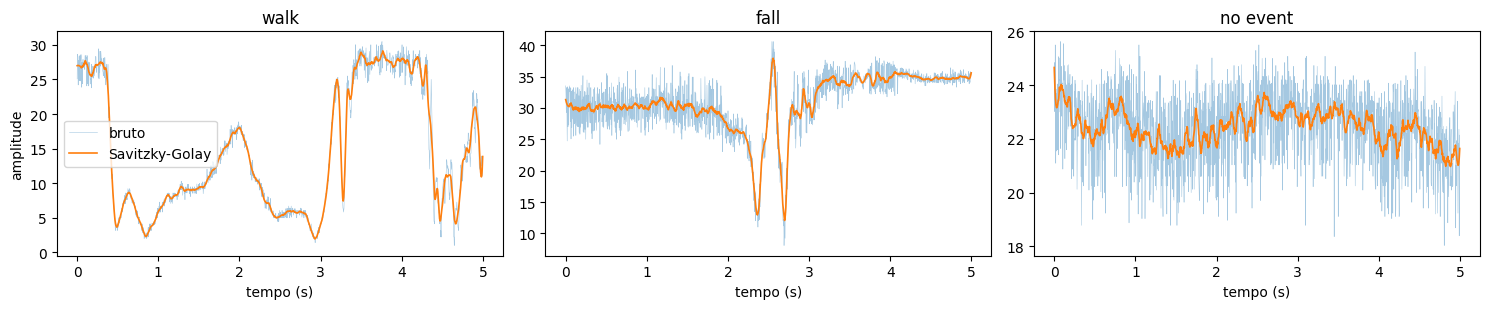

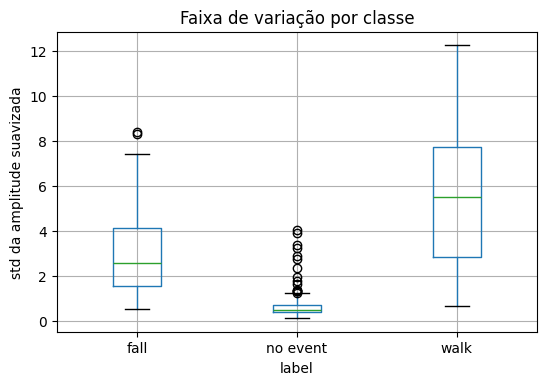

In [22]:
from scipy.signal import savgol_filter

def suaviza(x, janela=31, ordem=3):      # 31 pacotes ≈ 0,1 s a 320 Hz
    return savgol_filter(x.astype(np.float32), janela, ordem)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
t = np.arange(WIN) / FS
for ax, c in zip(axes, ['walk', 'fall', 'no event']):
    i = meta.index[meta.label == c][0]
    x = X[i, :, SUB]
    ax.plot(t, x, lw=0.4, alpha=0.4, label='bruto')
    ax.plot(t, suaviza(x), lw=1.2, label='Savitzky-Golay')
    ax.set_title(c); ax.set_xlabel('tempo (s)')
axes[0].set_ylabel('amplitude'); axes[0].legend()
plt.tight_layout(); plt.show()

meta['std_sub'] = [suaviza(X[i, :, SUB]).std() for i in range(len(X))]
ax = meta.boxplot(column='std_sub', by='label', figsize=(6, 4))
ax.set_title('Faixa de variação por classe'); ax.set_ylabel('std da amplitude suavizada')
plt.suptitle(''); plt.show()

In [23]:
ne = meta[meta.label == 'no event'].copy()
ne['origem'] = np.where(ne.start == 0, 'A1 sentado parado', 'A4 em pé parado')
print(ne.groupby('origem').std_sub.describe().round(2))

                   count  mean   std   min   25%   50%   75%   max
origem                                                            
A1 sentado parado  122.0  0.72  0.71  0.12  0.37  0.49  0.71  4.02
A4 em pé parado      8.0  0.70  0.40  0.35  0.44  0.55  0.80  1.33


## 10. Salvando no Drive

In [24]:
np.savez_compressed(f'{DATA_OUT}/alsaify_segmentos.npz', X=X, ids=meta.id.values)
meta.drop(columns=['std_sub']).to_csv(f'{DATA_OUT}/alsaify_meta.csv', index=False)

params = dict(dataset='Alsaify et al. 2020, Mendeley Data doi:10.17632/v38wjmz6f6.1 (CC BY 4.0)',
              FS=FS, WIN=WIN, SEED=SEED, ENVS=ENVS, PRE_FALL=PRE_FALL, MARGEM=MARGEM,
              N_POR_CLASSE=N_POR_CLASSE, dtype='float16',
              colunas='90 amplitudes = 3 antenas Rx x 30 subportadoras (csi_1_y_z)')
pd.Series(params).to_json(f'{DATA_OUT}/alsaify_params.json', indent=2)

for f in sorted(os.listdir(DATA_OUT)):
    print(f'{f:30s} {os.path.getsize(os.path.join(DATA_OUT, f))/1e6:8.1f} MB')

alsaify_meta.csv                    0.0 MB
alsaify_params.json                 0.0 MB
alsaify_segmentos.npz              67.9 MB


## O que me mandar

1. A tabela de durações e o intervalo entre atividades (seção 5).
2. Quantas janelas saíram de cada classe (seção 7).
3. As tabelas de split e de ambientes (seção 8).
4. Se der, um print dos gráficos das seções 5 e 9.

**Citação do dataset para o relatório:** B. A. Alsaify, M. M. Almazari, R. Alazrai, M. I. Daoud. *A dataset for Wi-Fi-based human activity recognition in line-of-sight and non-line-of-sight indoor environments.* Data in Brief 33 (2020) 106534. Dados: Mendeley Data, doi:10.17632/v38wjmz6f6.1.